In [ ]:
# CS4168 Data Mining — Group Project
## Preprocessing & Pipelines

**Dataset:** `tracks2026.csv` — Spotify audio features across 5 genres  
**Focus:** Data cleaning, feature engineering, and building proper sklearn pipelines ready for clustering, classification, and regression.


## 1. Imports

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.base import BaseEstimator, TransformerMixin

sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams['figure.dpi'] = 100


## 2. Load the Dataset

We load a fresh copy and immediately make a note of what we have before touching anything.


In [13]:
# tracks2026.csv sits in the same folder as this notebook
df_raw = pd.read_csv("tracks2026.csv")
print("Shape:", df_raw.shape)
print("\nColumn dtypes:")
print(df_raw.dtypes)
print("\nFirst few rows:")
df_raw.head()

Shape: (2000, 17)

Column dtypes:
track_id                str
popularity          float64
duration_ms           int64
explicit               bool
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
time_signature        int64
track_genre             str
dtype: object

First few rows:


,track_id,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5xmO5SbFOiVrRGrMQhL4Jk,44.0,203337,False,0.608,0.553,10,-3.493,1,0.0271,0.3930,0.000000,0.1530,0.541,143.993,3,r-n-b
1,5cF0dROlMOK5uNZtivgu50,83.0,208786,False,0.775,0.613,3,-4.586,0,0.0542,0.1090,0.000023,0.1340,0.797,100.066,4,pop
2,4OQ9XGe11ckizN2EBnNED2,49.0,262373,False,0.797,0.612,2,-9.043,0,0.0313,0.2710,0.000011,0.3140,0.919,118.162,4,synth-pop
3,6Grw9OtoslF9JrDJ6pgsQG,0.0,191733,False,0.582,0.829,9,-3.517,1,0.1930,0.0522,0.000000,0.2640,0.716,90.959,4,indie-pop
4,3fGpNiwYr981n72YY4DZvB,41.0,283706,False,0.705,0.713,4,-6.676,0,0.0437,0.2600,0.000016,0.0499,0.498,129.899,4,synth-pop


## 3. Data Audit

Before writing any pipeline code it's worth taking stock of what actually needs fixing.  
We check: missing values, duplicates, data types, and any obvious range issues.


In [14]:
# ── 3.1  Missing values ────────────────────────────────────────────────────────
missing = df_raw.isnull().sum()
missing_pct = (missing / len(df_raw) * 100).round(2)
audit = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
print("Columns with missing values:")
print(audit[audit['Missing Count'] > 0])


Columns with missing values:
              Missing Count  Missing %
popularity               40       2.00
danceability             40       2.00
energy                   40       2.00
loudness                 39       1.95
tempo                    40       2.00


In [15]:
# ── 3.2  Are missing rows the same across columns? ─────────────────────────────
# If the same rows are missing across multiple columns it suggests a
# data-collection failure for those tracks rather than random dropout.
pop_null_idx = df_raw[df_raw['popularity'].isnull()].index
print("Rows missing 'popularity'              :", len(pop_null_idx))
print("Same rows also missing 'danceability'  :", df_raw.loc[pop_null_idx, 'danceability'].isnull().sum())
print("Same rows also missing 'energy'        :", df_raw.loc[pop_null_idx, 'energy'].isnull().sum())
print("Same rows also missing 'tempo'         :", df_raw.loc[pop_null_idx, 'tempo'].isnull().sum())
print("Same rows also missing 'loudness'      :", df_raw.loc[pop_null_idx, 'loudness'].isnull().sum())
print()
print("Conclusion: the 40 missing rows are a coherent block — all audio")
print("features were unavailable together. Median imputation is appropriate")
print("since the fraction is only ~2% and the distributions are not heavily skewed.")


Rows missing 'popularity'              : 40
Same rows also missing 'danceability'  : 40
Same rows also missing 'energy'        : 40
Same rows also missing 'tempo'         : 40
Same rows also missing 'loudness'      : 39

Conclusion: the 40 missing rows are a coherent block — all audio
features were unavailable together. Median imputation is appropriate
since the fraction is only ~2% and the distributions are not heavily skewed.


In [16]:
# ── 3.3  Duplicate track IDs ───────────────────────────────────────────────────
n_dupes = df_raw['track_id'].duplicated().sum()
print(f"Duplicate track_id entries: {n_dupes}")
print()
print("We will drop duplicates, keeping the first occurrence.")
print("track_id itself won't be used as a feature — it's just an identifier.")


Duplicate track_id entries: 32

We will drop duplicates, keeping the first occurrence.
track_id itself won't be used as a feature — it's just an identifier.


In [17]:
# ── 3.4  Categorical and boolean columns ──────────────────────────────────────
print("'explicit' values  :", df_raw['explicit'].unique())
print("'track_genre' values:", df_raw['track_genre'].unique())
print()
print("'explicit' is a boolean — we'll cast it to int (0/1).")
print("'track_genre' is nominal — we'll one-hot encode it for regression/classification")
print("and drop it for clustering (as required by the spec).")


'explicit' values  : [False  True]
'track_genre' values: <StringArray>
['r-n-b', 'pop', 'synth-pop', 'indie-pop', 'hip-hop']
Length: 5, dtype: str

'explicit' is a boolean — we'll cast it to int (0/1).
'track_genre' is nominal — we'll one-hot encode it for regression/classification
and drop it for clustering (as required by the spec).


In [18]:
# ── 3.5  Numeric range checks ─────────────────────────────────────────────────
# Spotify documents the expected range for each feature.
# Anything outside those bounds would be a data quality issue.
expected_ranges = {
    'popularity'      : (0, 100),
    'danceability'    : (0, 1),
    'energy'          : (0, 1),
    'loudness'        : (-60, 0),
    'speechiness'     : (0, 1),
    'acousticness'    : (0, 1),
    'instrumentalness': (0, 1),
    'liveness'        : (0, 1),
    'valence'         : (0, 1),
    'tempo'           : (0, 300),
}

print(f"{'Feature':<20} {'Min':>8} {'Max':>8} {'Expected':>20} {'OK?':>5}")
print("-" * 65)
for col, (lo, hi) in expected_ranges.items():
    col_min = df_raw[col].min()
    col_max = df_raw[col].max()
    ok = '✓' if col_min >= lo and col_max <= hi else '✗ ISSUE'
    print(f"{col:<20} {col_min:>8.3f} {col_max:>8.3f} {str((lo, hi)):>20} {ok:>5}")


Feature                   Min      Max             Expected   OK?
-----------------------------------------------------------------
popularity              0.000  100.000             (0, 100)     ✓
danceability            0.185    0.953               (0, 1)     ✓
energy                  0.091    0.996               (0, 1)     ✓
loudness              -21.089 800000.000             (-60, 0) ✗ ISSUE
speechiness             0.022    0.515               (0, 1)     ✓
acousticness            0.000    0.990               (0, 1)     ✓
instrumentalness        0.000    0.962               (0, 1)     ✓
liveness                0.010    0.986               (0, 1)     ✓
valence                 0.036    0.990               (0, 1)     ✓
tempo                  51.037  205.895             (0, 300)     ✓


In [19]:
# ── 3.6  Skewness overview ────────────────────────────────────────────────────
# High skewness can hurt distance-based models (k-means, DBSCAN) even after
# standard scaling, because the scaled distribution will still be asymmetric.
skew = df_raw.select_dtypes('number').skew().sort_values(ascending=False).round(2)
print("Skewness of numeric features:")
print(skew)
print()
print("Highly skewed (|skew| > 2): instrumentalness, speechiness, liveness.")
print("We'll note this for clustering — these features may need log-transform.")


Skewness of numeric features:
loudness            44.28
instrumentalness     5.45
speechiness          2.47
liveness             2.47
duration_ms          1.04
acousticness         0.74
tempo                0.44
valence              0.02
key                 -0.02
popularity          -0.23
energy              -0.35
danceability        -0.44
mode                -0.57
time_signature      -4.71
dtype: float64

Highly skewed (|skew| > 2): instrumentalness, speechiness, liveness.
We'll note this for clustering — these features may need log-transform.


In [20]:
# ── 3.7  Key, mode, time_signature — ordinal or categorical? ──────────────────
print("'key' unique values        :", sorted(df_raw['key'].unique()))
print("'mode' unique values       :", df_raw['mode'].unique())
print("'time_signature' unique    :", sorted(df_raw['time_signature'].unique()))
print()
print("'key'           : 0–11, representing pitch classes (C, C#, D …).")
print("                  Not truly numeric — there is no ordering (11 is not")
print("                  'more key' than 0). We treat it as categorical.")
print()
print("'mode'          : binary (0 = minor, 1 = major). We keep as-is (0/1).")
print()
print("'time_signature': integer (1, 3, 4, 5). Mostly 4/4 music.")
print("                  We keep as numeric — there is a natural ordering here.")


'key' unique values        : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11)]
'mode' unique values       : [1 0]
'time_signature' unique    : [np.int64(1), np.int64(3), np.int64(4), np.int64(5)]

'key'           : 0–11, representing pitch classes (C, C#, D …).
                  Not truly numeric — there is no ordering (11 is not
                  'more key' than 0). We treat it as categorical.

'mode'          : binary (0 = minor, 1 = major). We keep as-is (0/1).

'time_signature': integer (1, 3, 4, 5). Mostly 4/4 music.
                  We keep as numeric — there is a natural ordering here.


## 4. Basic Cleaning Steps

These are one-off operations that happen before the pipeline —  
mostly removing things that should never appear as features.


In [21]:
df = df_raw.copy()

# Drop duplicate track_id rows (keep first occurrence)
before = len(df)
df = df.drop_duplicates(subset='track_id', keep='first')
print(f"Rows dropped (duplicate track_id): {before - len(df)}")
print(f"Rows remaining: {len(df)}")


Rows dropped (duplicate track_id): 32
Rows remaining: 1968


In [22]:
# Drop track_id — it's a string identifier with no predictive value
df = df.drop(columns=['track_id'])

# Cast 'explicit' boolean to int so sklearn doesn't complain
df['explicit'] = df['explicit'].astype(int)

print("Columns after cleaning:")
print(df.columns.tolist())
print()
print("Dtypes:")
print(df.dtypes)


Columns after cleaning:
['popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']

Dtypes:
popularity          float64
duration_ms           int64
explicit              int64
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
time_signature        int64
track_genre             str
dtype: object


In [23]:
# Quick sanity check — confirm shape and no unexpected changes
print("Shape after cleaning:", df.shape)
print("Missing values remaining:")
print(df.isnull().sum()[df.isnull().sum() > 0])


Shape after cleaning: (1968, 16)
Missing values remaining:
popularity      39
danceability    39
energy          39
loudness        38
tempo           39
dtype: int64


### 5. Exploratory Data Analysis (EDA)

1. Dataset Overview

In [57]:
df.shape
df.info()
df.head()
df.describe()

<class 'pandas.DataFrame'>
Index: 1968 entries, 0 to 1999
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   popularity        1929 non-null   float64
 1   duration_ms       1968 non-null   int64  
 2   explicit          1968 non-null   int64  
 3   danceability      1929 non-null   float64
 4   energy            1929 non-null   float64
 5   key               1968 non-null   int64  
 6   loudness          1930 non-null   float64
 7   mode              1968 non-null   int64  
 8   speechiness       1968 non-null   float64
 9   acousticness      1968 non-null   float64
 10  instrumentalness  1968 non-null   float64
 11  liveness          1968 non-null   float64
 12  valence           1968 non-null   float64
 13  tempo             1929 non-null   float64
 14  time_signature    1968 non-null   int64  
 15  track_genre       1968 non-null   str    
dtypes: float64(10), int64(5), str(1)
memory usage: 261.4 KB


,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,1929.000000,1968.000000,1968.000000,1929.000000,1929.000000,1968.000000,1930.000000,1968.000000,1968.000000,1968.000000,1968.000000,1968.000000,1968.000000,1929.000000,1968.000000
mean,39.542768,217879.221545,0.110772,0.634973,0.632610,5.289634,407.115090,0.643293,0.078145,0.298887,0.030356,0.180797,0.540811,120.168356,3.911585
std,29.153485,56991.653309,0.313930,0.138410,0.190012,3.566986,18210.226737,0.479149,0.076095,0.280468,0.120209,0.150462,0.236448,28.527713,0.423398
min,0.000000,60000.000000,0.000000,0.185000,0.090900,0.000000,-21.089000,0.000000,0.022100,0.000007,0.000000,0.009860,0.035900,51.037000,1.000000
25%,1.000000,181210.000000,0.000000,0.546000,0.506000,2.000000,-9.008000,0.000000,0.034400,0.052650,0.000000,0.093600,0.352750,97.014000,4.000000
50%,45.000000,211343.500000,0.000000,0.645000,0.644000,5.000000,-6.933500,1.000000,0.047300,0.200000,0.000007,0.121000,0.536500,118.879000,4.000000
75%,65.000000,246460.000000,0.000000,0.737000,0.780000,8.000000,-5.390750,1.000000,0.082800,0.493000,0.000662,0.222000,0.732500,139.802000,4.000000
max,100.000000,561133.000000,1.000000,0.953000,0.996000,11.000000,800000.000000,1.000000,0.515000,0.990000,0.962000,0.986000,0.990000,205.895000,5.000000


Observations:
1. The dataset contains a mix of numerical audio features (e.g., danceability, energy, loudness, tempo) and categorical variables (e.g., track_genre, key, mode).
2. Most numerical features are already normalized between 0 and 1 (e.g., danceability, energy), while others such as tempo and loudness vary in scale.


2. Missing Values Analysis

In [58]:
df.isnull().sum()

popularity          39
duration_ms          0
explicit             0
danceability        39
energy              39
key                  0
loudness            38
mode                 0
speechiness          0
acousticness         0
instrumentalness     0
liveness             0
valence              0
tempo               39
time_signature       0
track_genre          0
dtype: int64

Observations:

1.The dataset has a small number of missing values (around 38–39) mainly in numerical audio features such as popularity, danceability, energy, loudness, and tempo, while all other features are fully complete.
2.The missing values are concentrated in specific audio-related attributes, which may be associated with variations in data collection or feature recording processes.
3.As these features are important for clustering and predictive analysis, suitable imputation methods are recommended instead of removing records to maintain dataset consistency.

3. Univariate Analysis

Distribution of Numerical Features

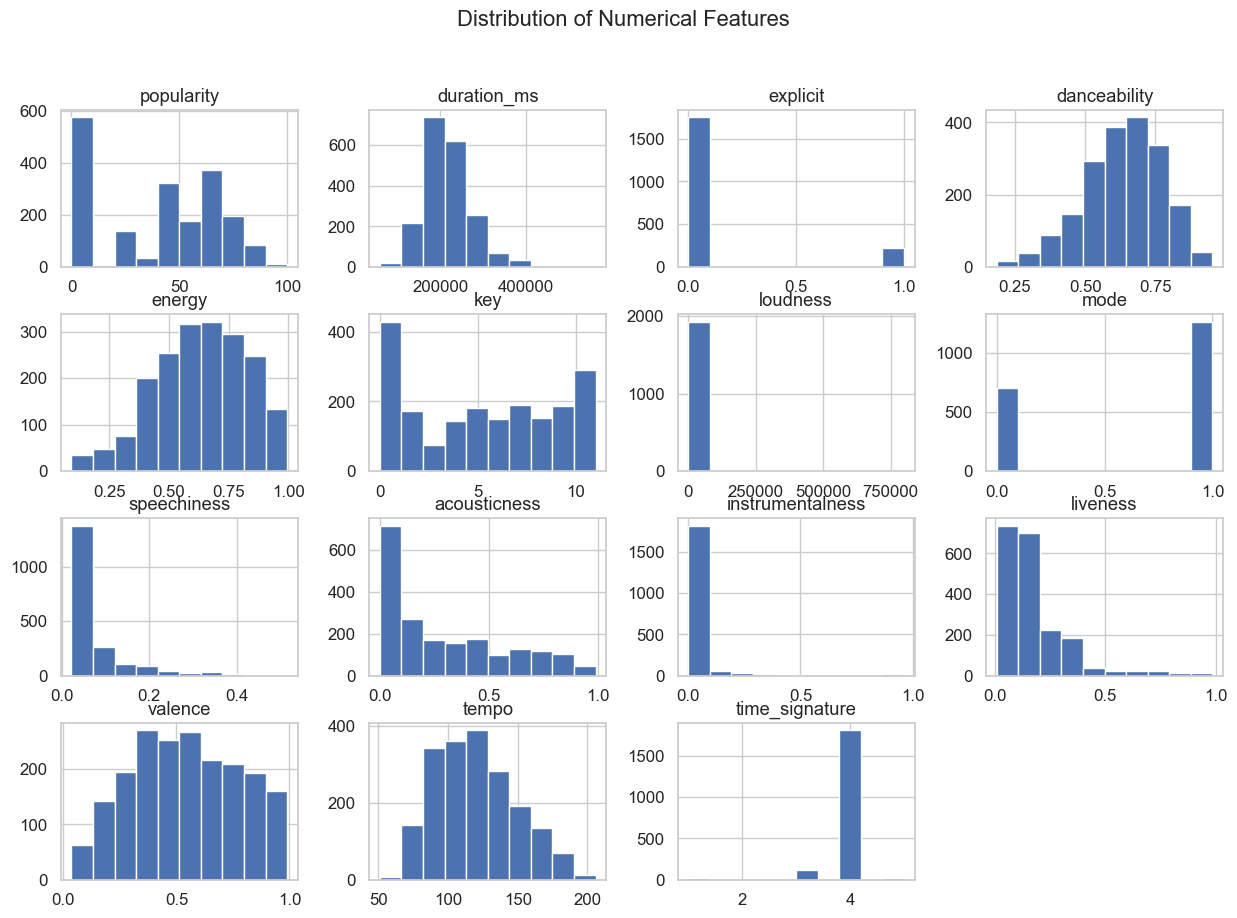

In [59]:
import matplotlib.pyplot as plt

df.hist(figsize=(15, 10))
plt.suptitle("Distribution of Numerical Features")
plt.show()

Observations
1. Features such as danceability, energy, and valence are relatively well distributed.
2. Loudness appears left-skewed, indicating most songs have high loudness values.
3. Tempo shows a wide spread, suggesting variability in musical styles.
4. Some features exhibit skewness, indicating non-normal distributions.

Insight for Modelling
1. Skewed distributions may require normalization or transformation to improve model performance.
2. Feature scaling is essential to ensure all variables contribute equally in distance-based algorithms such as K-Means clustering.

4. Outlier Detection

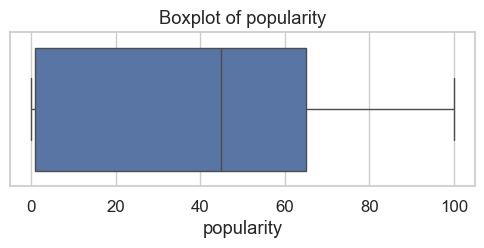

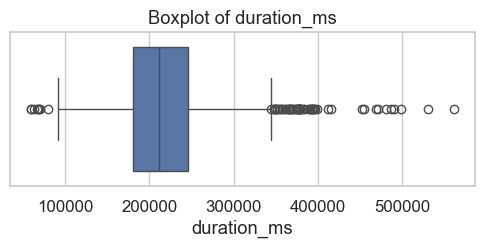

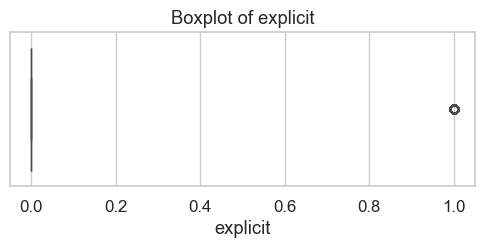

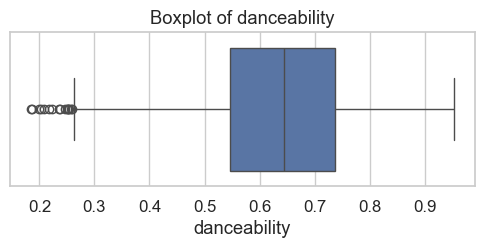

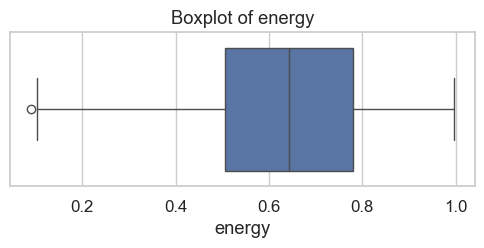

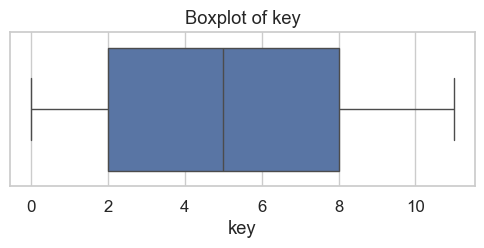

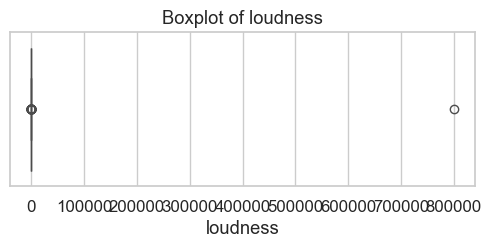

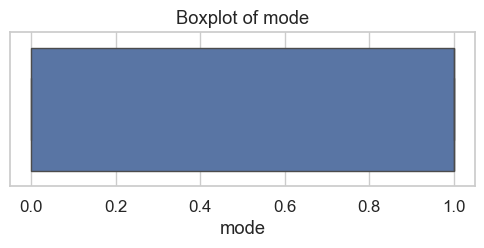

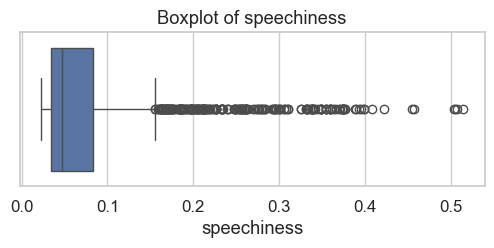

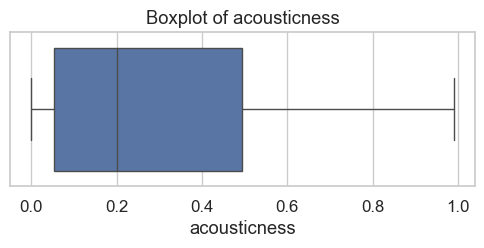

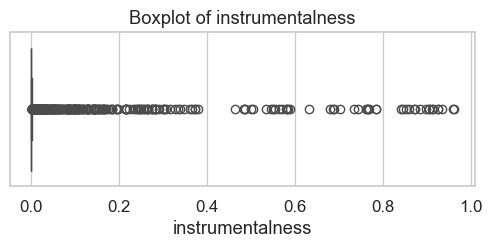

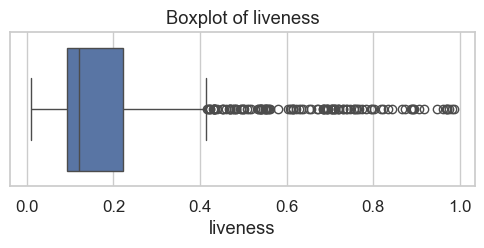

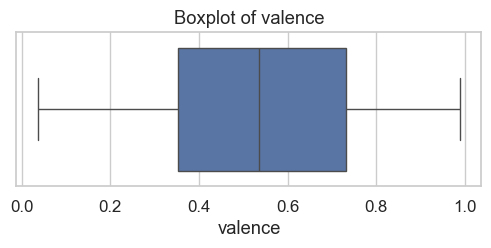

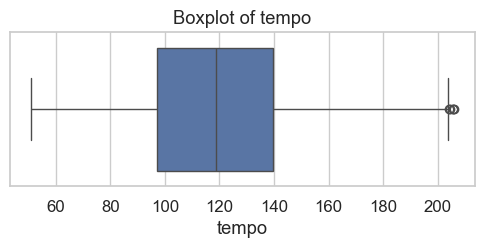

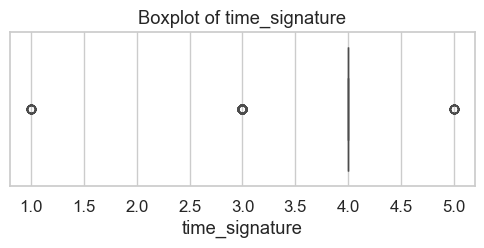

In [60]:
import seaborn as sns
import numpy as np

num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    plt.figure(figsize=(6,2))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

Observations:
1. Outliers are visible in features such as:
tempo
duration_ms
2. Most normalized features (0–1 range) show fewer extreme values.

5. Correlation Analysis

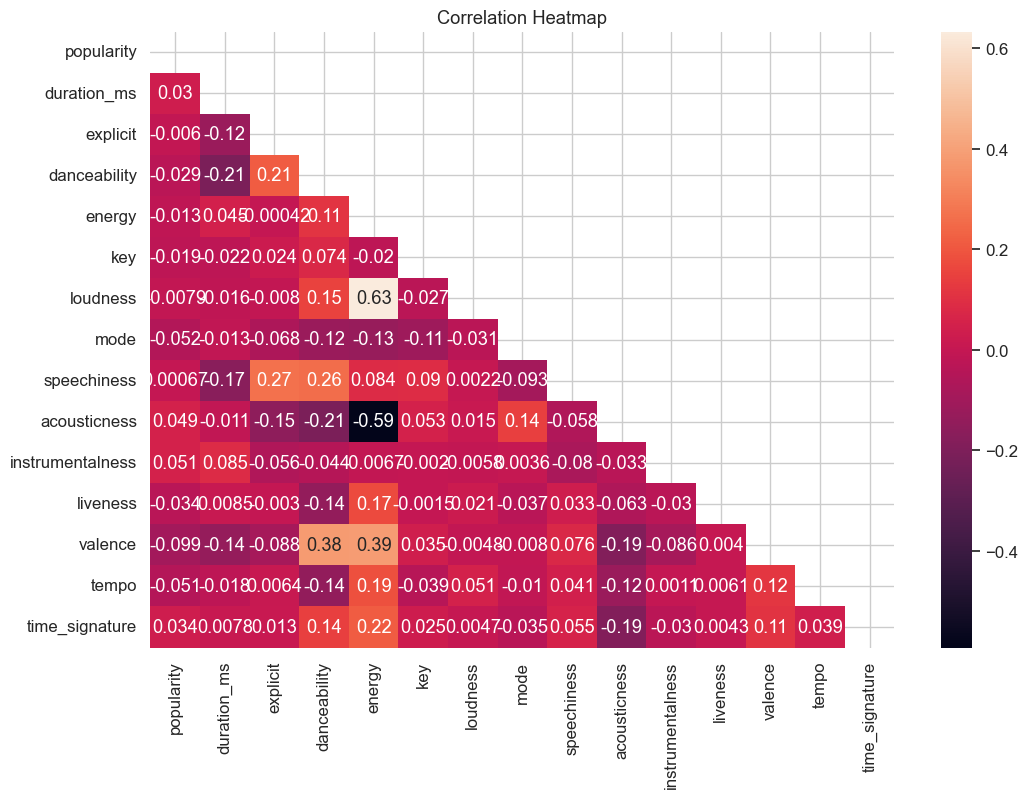

In [61]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(12,8))
plt.xticks(rotation=45)
plt.yticks(rotation=0)
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True)
plt.title("Correlation Heatmap")
plt.show()

Observations:
1. The strongest positive correlation is observed between energy and loudness (≈ 0.63), indicating that higher energy tracks tend to be louder.
2. A notable negative correlation exists between acousticness and energy (≈ -0.59), suggesting that acoustic songs are generally less energetic.
3. Moderate positive relationships are seen between danceability and valence (≈ 0.38), indicating that more danceable songs tend to have a more positive mood.
4. Most other feature pairs show weak correlations (close to 0), implying low linear dependency among the majority of audio features.

6. Pairwise Relationships

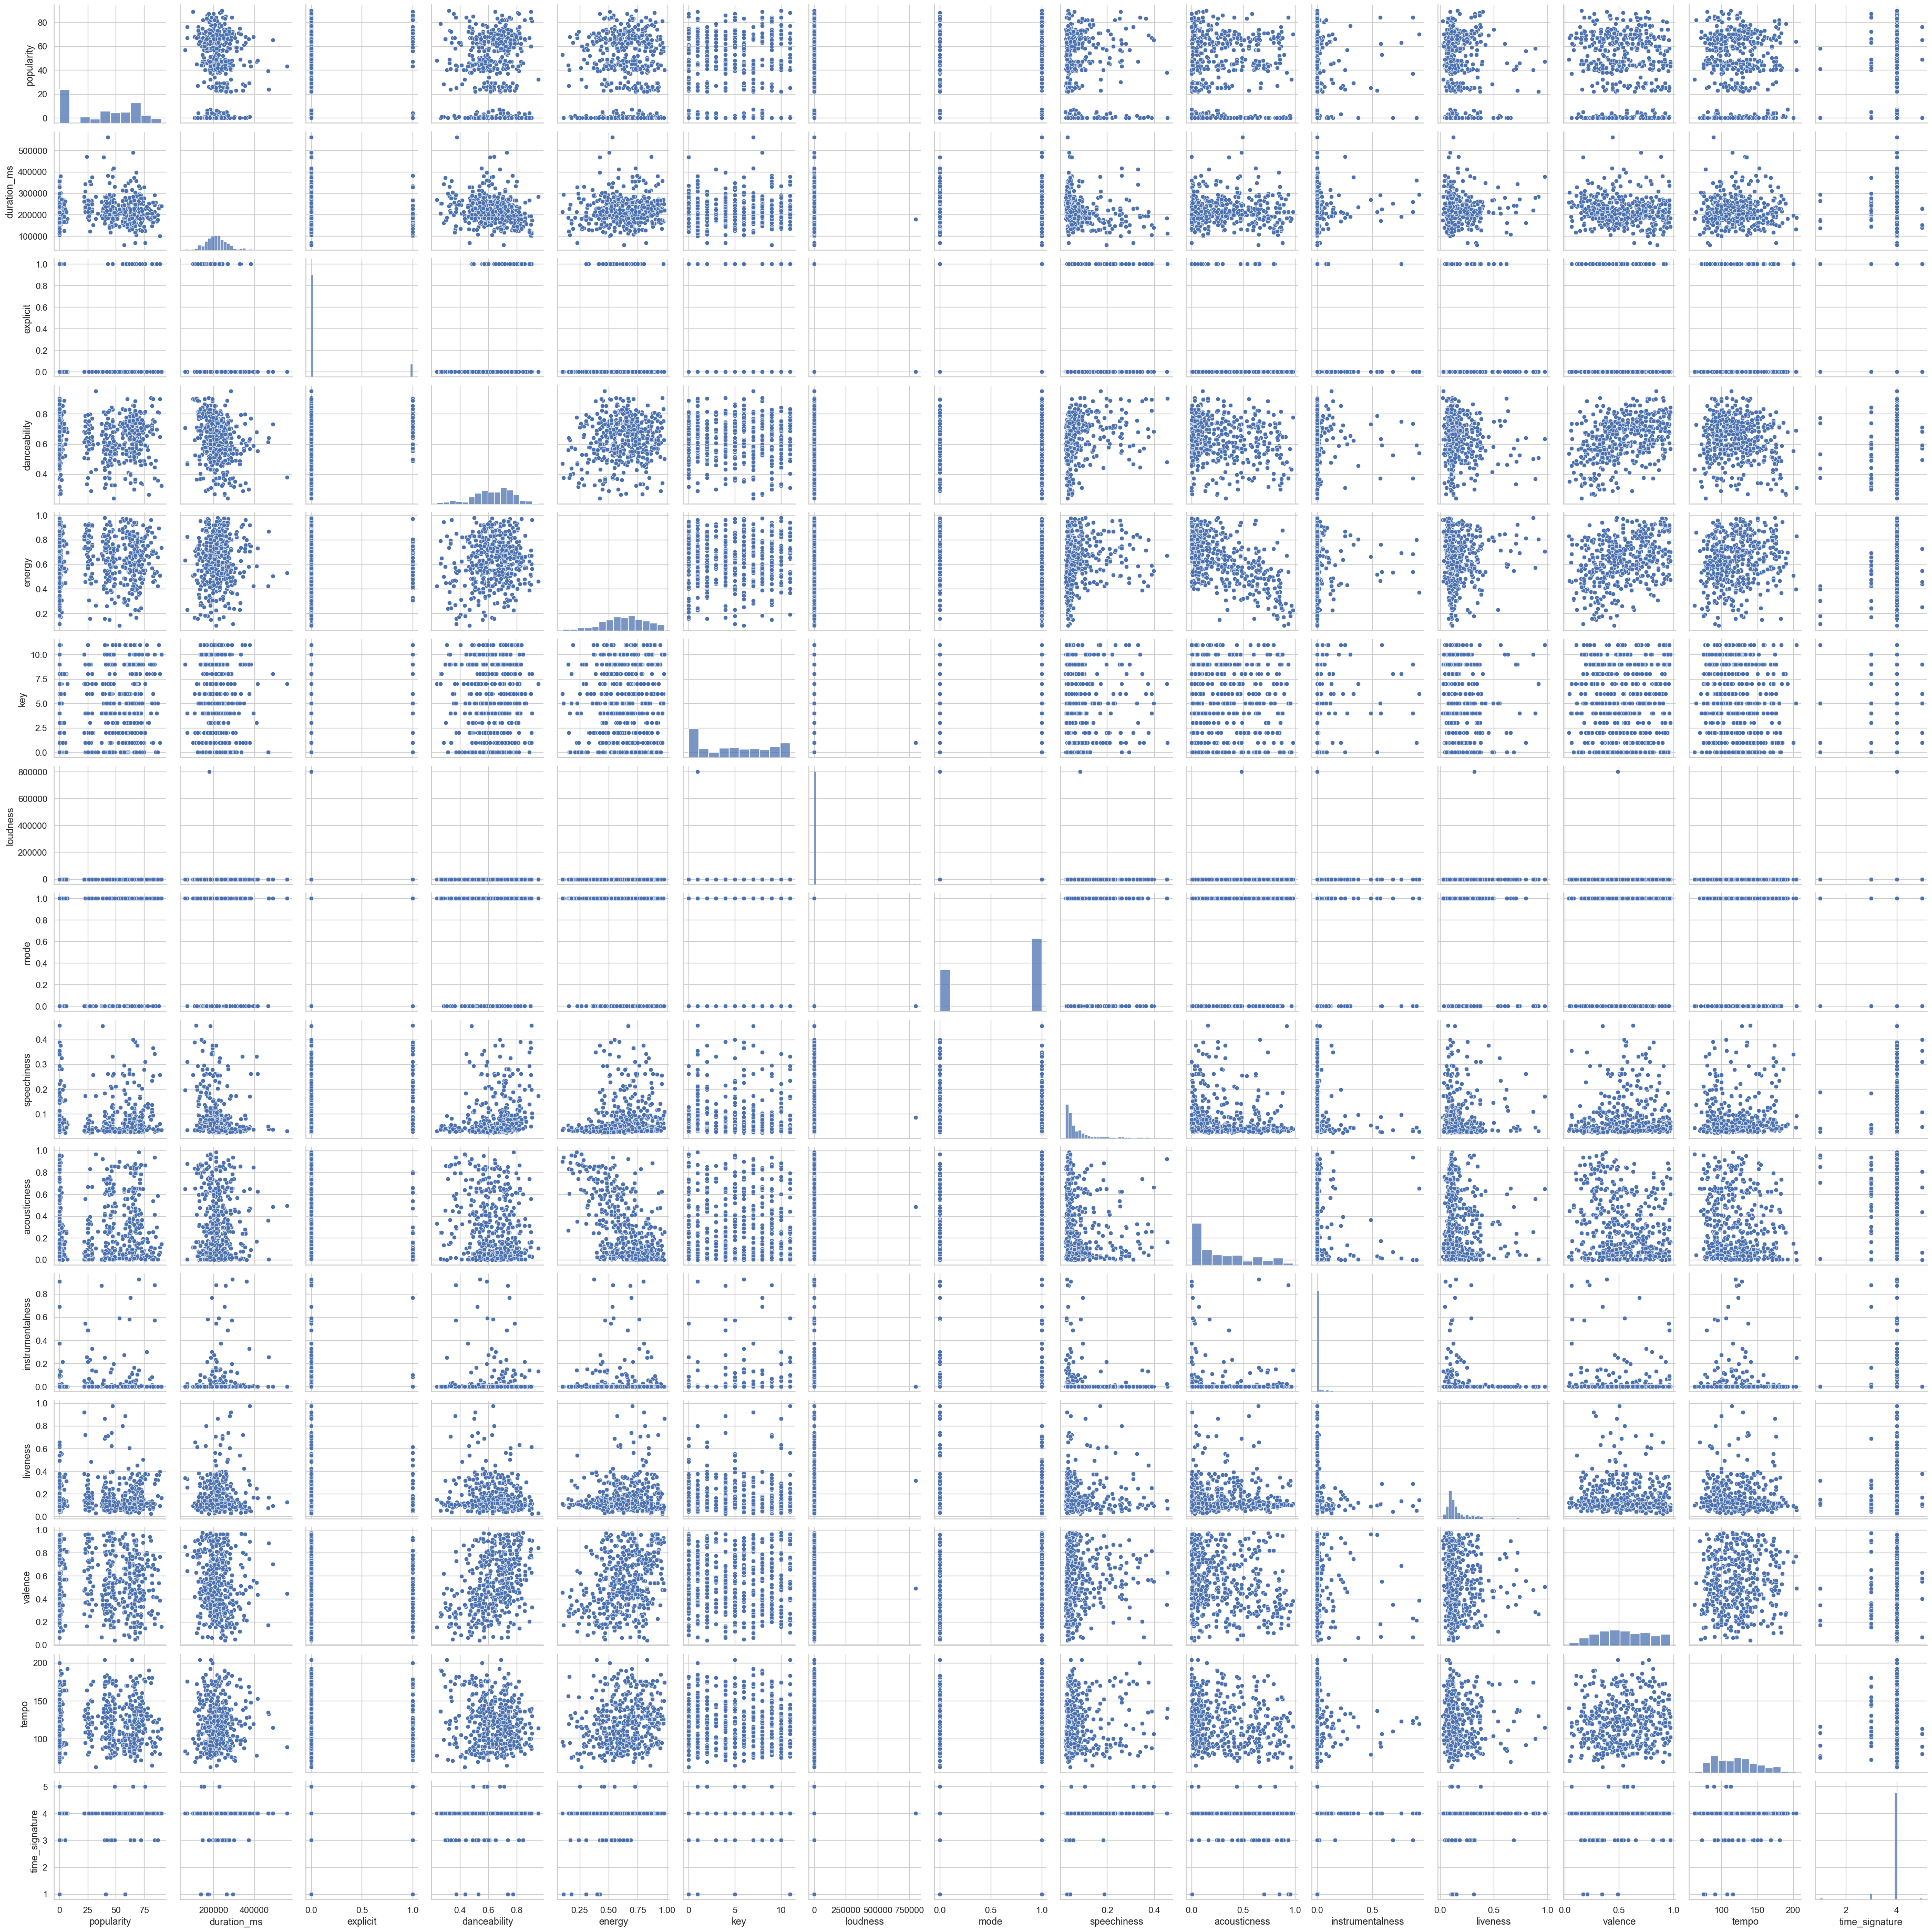

In [62]:
sns.pairplot(
    df.sample(500),
    height=2.5,
    aspect=1,
    diag_kind="hist"
)
plt.show()

Observations:
1. Distinct clustering patterns can be observed in the feature space, indicating the presence of natural groupings within the data.
2. A negative correlation is observed between acousticness and energy, suggesting that tracks with higher acousticness tend to have lower energy levels.
3. A positive correlation is observed between energy and loudness, indicating that more energetic tracks are generally louder.

7. Categorical Analysis (Genre Distribution)

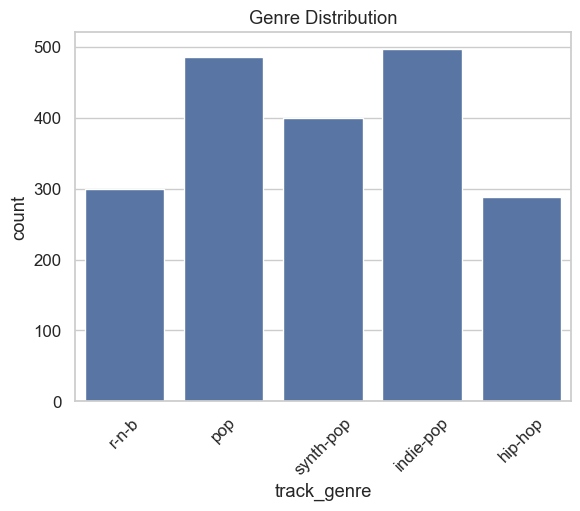

In [63]:
sns.countplot(x='track_genre', data=df)
plt.xticks(rotation=45)
plt.title("Genre Distribution")
plt.show()

Observations:
1. The dataset shows an uneven distribution across genres, indicating a moderate level of class imbalance.
2. Pop and Indie-Pop have the highest representation, with approximately 500 samples each.
3. Synth-Pop has a moderate representation with around 400 samples.
4. R-n-B and Hip-Hop have comparatively fewer samples, with roughly 300 each.

8. Feature vs Genre Analysis

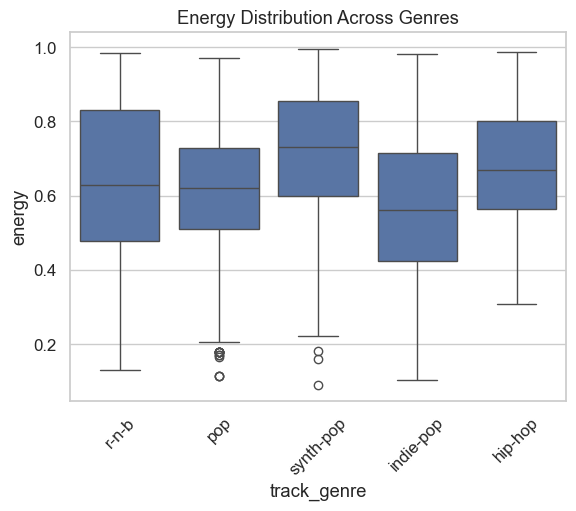

In [64]:
sns.boxplot(x='track_genre', y='energy', data=df)
plt.xticks(rotation=45)
plt.title("Energy Distribution Across Genres")
plt.show()

Observations:
1. Pop and synth‑pop show relatively higher median energy, suggesting these genres tend to have more energetic tracks.
2. R‑n‑b and indie‑pop display wider variability with several low‑energy outliers, indicating more diversity in track intensity.
3. Hip‑hop has a moderately high median with a tighter spread, meaning its energy levels are more consistent across tracks.
4. This indicates that audio features are strong predictors of genre.

9. Feature Scaling Consideration

In [65]:
df.describe()

,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,1929.000000,1968.000000,1968.000000,1929.000000,1929.000000,1968.000000,1930.000000,1968.000000,1968.000000,1968.000000,1968.000000,1968.000000,1968.000000,1929.000000,1968.000000
mean,39.542768,217879.221545,0.110772,0.634973,0.632610,5.289634,407.115090,0.643293,0.078145,0.298887,0.030356,0.180797,0.540811,120.168356,3.911585
std,29.153485,56991.653309,0.313930,0.138410,0.190012,3.566986,18210.226737,0.479149,0.076095,0.280468,0.120209,0.150462,0.236448,28.527713,0.423398
min,0.000000,60000.000000,0.000000,0.185000,0.090900,0.000000,-21.089000,0.000000,0.022100,0.000007,0.000000,0.009860,0.035900,51.037000,1.000000
25%,1.000000,181210.000000,0.000000,0.546000,0.506000,2.000000,-9.008000,0.000000,0.034400,0.052650,0.000000,0.093600,0.352750,97.014000,4.000000
50%,45.000000,211343.500000,0.000000,0.645000,0.644000,5.000000,-6.933500,1.000000,0.047300,0.200000,0.000007,0.121000,0.536500,118.879000,4.000000
75%,65.000000,246460.000000,0.000000,0.737000,0.780000,8.000000,-5.390750,1.000000,0.082800,0.493000,0.000662,0.222000,0.732500,139.802000,4.000000
max,100.000000,561133.000000,1.000000,0.953000,0.996000,11.000000,800000.000000,1.000000,0.515000,0.990000,0.962000,0.986000,0.990000,205.895000,5.000000


Observations:
1. The dataset contains features measured on different numerical scales, highlighting the need for feature scaling before applying distance‑based algorithms such as K‑Means or K‑Nearest Neighbors.
2. Tempo shows a wide numerical range (approximately 20–200 BPM), indicating substantial variability in track speed across samples.
3. Loudness values are negative because they are measured in decibels relative to a reference level, where 0 dB represents the maximum loudness.
4. Danceability is a normalized feature ranging from 0 to 1, making it directly comparable across all tracks.



### Insights from Exploratory Data Analysis:

1. The dataset contains a rich set of numerical audio features (e.g., energy, danceability, loudness, tempo) that are suitable for both clustering and predictive modelling.
2. Several features such as energy and loudness are strongly positively correlated, indicating redundancy. This suggests that some features may be reduced or combined using techniques like PCA to improve model efficiency.
3. Many numerical variables show skewed distributions and varying scales, meaning that feature scaling and normalization are essential before applying machine learning algorithms, especially distance-based methods like K-Means.
4. Outliers are present in features such as tempo and duration, which may influence clustering performance and need appropriate handling (e.g., removal, capping, or robust scaling).
5. The dataset shows variation across genres, with certain genres exhibiting distinct patterns in energy, acousticness, and danceability. This indicates that features are meaningful for genre classification tasks.
6. There is likely class imbalance in genre distribution, which may affect supervised learning models and may require resampling techniques if used for classification.
7. Overall, the dataset demonstrates clear structure and meaningful relationships between audio features, making it suitable for both unsupervised learning (clustering) and supervised learning (prediction tasks).

## 6. Define Feature Groups

We separate features into groups so we can apply the right transformer to each.  
This is the foundation of a `ColumnTransformer` pipeline.


In [24]:
# Features that have missing values and need imputation before scaling
continuous_with_nan = ['danceability', 'energy', 'loudness', 'tempo']

# Continuous features with no missing values — still need scaling
continuous_no_nan = [
    'duration_ms', 'speechiness', 'acousticness',
    'instrumentalness', 'liveness', 'valence'
]

# Binary / low-cardinality integer — no scaling needed
binary_features = ['explicit', 'mode']

# Integer features that represent a musical scale — treat as numeric, scale
ordinal_numeric = ['time_signature']

# Nominal categorical — needs encoding
# 'key' is treated as categorical (pitch class, not a number)
categorical_features = ['key', 'track_genre']

# Confirm nothing is double-counted or forgotten
all_feature_cols = (
    continuous_with_nan + continuous_no_nan +
    binary_features + ordinal_numeric + categorical_features
)

# 'popularity' is our target — shouldn't appear in features
remaining = set(df.columns) - {'popularity'} - set(all_feature_cols)
print("Unassigned columns (should be empty):", remaining)
print()
print("Feature groups:")
print(f"  continuous_with_nan : {continuous_with_nan}")
print(f"  continuous_no_nan   : {continuous_no_nan}")
print(f"  binary_features     : {binary_features}")
print(f"  ordinal_numeric     : {ordinal_numeric}")
print(f"  categorical         : {categorical_features}")


Unassigned columns (should be empty): set()

Feature groups:
  continuous_with_nan : ['danceability', 'energy', 'loudness', 'tempo']
  continuous_no_nan   : ['duration_ms', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence']
  binary_features     : ['explicit', 'mode']
  ordinal_numeric     : ['time_signature']
  categorical         : ['key', 'track_genre']


## 7. Custom Transformer — Log Transform for Skewed Features

`instrumentalness`, `speechiness`, and `liveness` are all heavily right-skewed  
(skew > 2). Standard scaling alone won't fix a distributional problem —  
we need to compress the long tail first with `log1p` (log(1 + x)).

We write this as a proper sklearn transformer so it slots neatly into a pipeline  
and is applied only at fit time (respecting the train/test boundary).


In [25]:
class Log1pTransformer(BaseEstimator, TransformerMixin):
    """
    Applies np.log1p column-wise to compress right-skewed distributions.
    Suitable for non-negative features like speechiness, liveness,
    instrumentalness. log1p(x) = log(1 + x) handles zeros cleanly.
    """

    def fit(self, X, y=None):
        return self   # stateless — nothing to learn

    def transform(self, X, y=None):
        return np.log1p(X)

# Quick test on a toy array
sample = np.array([[0, 0.001, 0.1, 0.5, 0.962]])
print("Before log1p:", sample)
print("After  log1p:", Log1pTransformer().transform(sample))


Before log1p: [[0.    0.001 0.1   0.5   0.962]]
After  log1p: [[0.         0.0009995  0.09531018 0.40546511 0.67396436]]


## 8. Preprocessing Pipeline — Clustering

For clustering we **drop `track_genre`** as required by the spec.  
`popularity` is also excluded because we don't want the cluster structure  
to simply reflect the target variable we'll predict later.

We apply:
- **Median imputation** on features with missing values (robust to outliers)
- **Log1p transform** on heavily skewed features before scaling
- **StandardScaler** on all continuous features (k-means and DBSCAN are both distance-based)
- **No encoding** of `key` or `track_genre` — both are dropped for clustering


In [26]:
# Features for clustering (drop genre, popularity, key)
# 'key' is excluded here — pitch class has no distance-interpretable ordering
cluster_continuous_nan = continuous_with_nan        # impute + scale
cluster_continuous_ok   = continuous_no_nan         # scale only
cluster_skewed          = ['speechiness', 'acousticness', 'instrumentalness', 'liveness']
cluster_binary          = binary_features           # keep as-is (0/1 already scaled)
cluster_ordinal         = ordinal_numeric           # scale

# Remove skewed features from the 'no_nan' group to avoid double-processing
cluster_continuous_ok_only = [f for f in cluster_continuous_ok if f not in cluster_skewed]

print("Pipeline groups for clustering:")
print(f"  Impute + Scale       : {cluster_continuous_nan}")
print(f"  Log1p + Scale        : {cluster_skewed}")
print(f"  Scale only           : {cluster_continuous_ok_only + cluster_ordinal}")
print(f"  Pass through (binary): {cluster_binary}")


Pipeline groups for clustering:
  Impute + Scale       : ['danceability', 'energy', 'loudness', 'tempo']
  Log1p + Scale        : ['speechiness', 'acousticness', 'instrumentalness', 'liveness']
  Scale only           : ['duration_ms', 'valence', 'time_signature']
  Pass through (binary): ['explicit', 'mode']


In [27]:
# ── Subpipelines ─────────────────────────────────────────────────────────────

# For features with NaN: impute median then scale
pipe_impute_scale = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler())
])

# For highly skewed features: log-compress then scale (no NaN in these)
pipe_log_scale = Pipeline([
    ('log',    Log1pTransformer()),
    ('scaler', StandardScaler())
])

# For features that just need scaling
pipe_scale_only = Pipeline([
    ('scaler', StandardScaler())
])

# ── ColumnTransformer ─────────────────────────────────────────────────────────
clustering_preprocessor = ColumnTransformer(
    transformers=[
        ('impute_scale', pipe_impute_scale,  cluster_continuous_nan),
        ('log_scale',    pipe_log_scale,     cluster_skewed),
        ('scale_only',   pipe_scale_only,    cluster_continuous_ok_only + cluster_ordinal),
        ('passthrough',  'passthrough',      cluster_binary),
    ],
    remainder='drop'   # drops track_genre, popularity, key — intentional
)

print("Clustering preprocessor defined.")
print("Remainder='drop' ensures track_genre, key, and popularity are excluded.")


Clustering preprocessor defined.
Remainder='drop' ensures track_genre, key, and popularity are excluded.


In [28]:
# ── Fit and transform the clustering data ─────────────────────────────────────
# Use rows where popularity is not null — 40 rows have no audio features either,
# so they'd produce all-NaN rows even after imputation on the *other* columns.
# The imputer handles the within-group NaNs; rows that are entirely missing in
# their audio features would just get median-filled, which is fine too.

X_cluster_raw = df.drop(columns=['popularity'])  # drop target

X_cluster = clustering_preprocessor.fit_transform(X_cluster_raw)

# Get output feature names for reference
output_names = (
    cluster_continuous_nan +
    cluster_skewed +
    cluster_continuous_ok_only + cluster_ordinal +
    cluster_binary
)

print("Shape after preprocessing:", X_cluster.shape)
print("Features included:", output_names)
print()
print("Each column is now standardised (mean≈0, std≈1) or log-compressed first.")
print("This puts all features on an equal footing for distance calculations.")


Shape after preprocessing: (1968, 13)
Features included: ['danceability', 'energy', 'loudness', 'tempo', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'duration_ms', 'valence', 'time_signature', 'explicit', 'mode']

Each column is now standardised (mean≈0, std≈1) or log-compressed first.
This puts all features on an equal footing for distance calculations.


In [29]:
# ── Sanity check: mean and std of transformed output ─────────────────────────
X_df = pd.DataFrame(X_cluster, columns=output_names)
stats = X_df.describe().loc[['mean', 'std']].round(3)
print("Post-transform stats (should be ≈ mean=0, std=1 for scaled features):")
print(stats)


Post-transform stats (should be ≈ mean=0, std=1 for scaled features):
      danceability  energy  loudness  tempo  speechiness  acousticness  \
mean          -0.0    -0.0       0.0    0.0          0.0           0.0   
std            1.0     1.0       1.0    1.0          1.0           1.0   

      instrumentalness  liveness  duration_ms  valence  time_signature  \
mean               0.0      -0.0         -0.0     -0.0            -0.0   
std                1.0       1.0          1.0      1.0             1.0   

      explicit   mode  
mean     0.111  0.643  
std      0.314  0.479  


## 9. Preprocessing Pipeline — Classification

For classification we:
1. Create the binary target `popularity_binary`
2. Keep `track_genre` and encode it with one-hot encoding
3. Encode `key` as one-hot (12 pitch classes — no numeric ordering)
4. Drop the original `popularity` column as per the spec


In [30]:
# ── 8.1  Build the classification dataset ─────────────────────────────────────

df_clf = df.copy()

# Compute median on the non-null rows
median_pop = df_clf['popularity'].median()
print(f"Median popularity (used as binary threshold): {median_pop}")

# Create binary target
# Only rows where popularity is not null get a valid label
df_clf['popularity_binary'] = (df_clf['popularity'] > median_pop).astype(int)

# Drop original popularity — spec requires this
df_clf = df_clf.drop(columns=['popularity'])

print(f"\nClass distribution:")
print(df_clf['popularity_binary'].value_counts())
print(f"\nClass balance: {df_clf['popularity_binary'].value_counts(normalize=True).round(3).to_dict()}")


Median popularity (used as binary threshold): 45.0

Class distribution:
popularity_binary
0    1026
1     942
Name: count, dtype: int64

Class balance: {0: 0.521, 1: 0.479}


In [31]:
# ── 8.2  Drop rows where we have no label ─────────────────────────────────────
# The 40 rows with missing popularity cannot be labelled — we drop them.
# (They were missing their audio features too, so imputation wouldn't recover them.)
before = len(df_clf)
df_clf = df_clf.dropna(subset=['popularity_binary'])
# popularity_binary is int from a bool, but the NaN rows gave NaN before astype
# Re-check: actually astype(int) on NaN gives NaN before dropna — confirm:
df_clf = df_clf.dropna()
print(f"Rows dropped (unlabelled): {before - len(df_clf)}")
print(f"Rows remaining: {len(df_clf)}")


Rows dropped (unlabelled): 39
Rows remaining: 1929


In [32]:
# ── 8.3  Define X and y ────────────────────────────────────────────────────────
X_clf = df_clf.drop(columns=['popularity_binary'])
y_clf = df_clf['popularity_binary']

print("X shape:", X_clf.shape)
print("y shape:", y_clf.shape)
print("y dtype:", y_clf.dtype)


X shape: (1929, 15)
y shape: (1929,)
y dtype: int64


In [33]:
# ── 8.4  Feature groups for classification ────────────────────────────────────
# Same logic as clustering but now we include track_genre (one-hot)
# and key (one-hot — 12 pitch classes, not numeric).

clf_impute_scale   = continuous_with_nan                                          # impute + scale
clf_skewed         = ['speechiness', 'acousticness', 'instrumentalness', 'liveness']
clf_scale_only     = [f for f in continuous_no_nan if f not in clf_skewed] + ordinal_numeric
clf_binary         = binary_features
clf_onehot         = ['track_genre', 'key']   # nominal — one-hot encode

print("Classification feature groups:")
print(f"  Impute + Scale : {clf_impute_scale}")
print(f"  Log1p + Scale  : {clf_skewed}")
print(f"  Scale only     : {clf_scale_only}")
print(f"  Binary passthru: {clf_binary}")
print(f"  One-hot encode : {clf_onehot}")


Classification feature groups:
  Impute + Scale : ['danceability', 'energy', 'loudness', 'tempo']
  Log1p + Scale  : ['speechiness', 'acousticness', 'instrumentalness', 'liveness']
  Scale only     : ['duration_ms', 'valence', 'time_signature']
  Binary passthru: ['explicit', 'mode']
  One-hot encode : ['track_genre', 'key']


In [34]:
# ── 8.5  Build the classification preprocessor ───────────────────────────────
from sklearn.preprocessing import OneHotEncoder

pipe_onehot = Pipeline([
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

clf_preprocessor = ColumnTransformer(
    transformers=[
        ('impute_scale', pipe_impute_scale,  clf_impute_scale),
        ('log_scale',    pipe_log_scale,     clf_skewed),
        ('scale_only',   pipe_scale_only,    clf_scale_only),
        ('passthrough',  'passthrough',      clf_binary),
        ('onehot',       pipe_onehot,        clf_onehot),
    ],
    remainder='drop'
)

print("Classification preprocessor defined.")


Classification preprocessor defined.


In [35]:
# ── 8.6  Train / test split — before fitting the preprocessor ─────────────────
# IMPORTANT: we split BEFORE fitting the preprocessor.
# Fitting on the full dataset before splitting would leak test statistics
# (e.g. the imputer's median) into the test set — that's data leakage.

from sklearn.model_selection import train_test_split

X_clf_train, X_clf_test, y_clf_train, y_clf_test = train_test_split(
    X_clf, y_clf,
    test_size=0.2,
    random_state=42,
    stratify=y_clf    # preserve class balance in both splits
)

print(f"Train size : {X_clf_train.shape[0]} rows")
print(f"Test size  : {X_clf_test.shape[0]} rows")
print(f"Train class balance: {y_clf_train.value_counts(normalize=True).round(3).to_dict()}")
print(f"Test  class balance: {y_clf_test.value_counts(normalize=True).round(3).to_dict()}")


Train size : 1543 rows
Test size  : 386 rows
Train class balance: {0: 0.511, 1: 0.489}
Test  class balance: {0: 0.513, 1: 0.487}


In [36]:
# ── 8.7  Fit preprocessor on training data only, then transform both sets ─────
X_clf_train_prep = clf_preprocessor.fit_transform(X_clf_train)
X_clf_test_prep  = clf_preprocessor.transform(X_clf_test)

print(f"Train after preprocessing: {X_clf_train_prep.shape}")
print(f"Test  after preprocessing: {X_clf_test_prep.shape}")
print()
print("The extra columns compared to clustering come from one-hot encoding")
print("track_genre (5 categories) and key (12 pitch classes).")


Train after preprocessing: (1543, 30)
Test  after preprocessing: (386, 30)

The extra columns compared to clustering come from one-hot encoding
track_genre (5 categories) and key (12 pitch classes).


## 10. Preprocessing Pipeline — Regression

Regression predicts the **original popularity score** (0–100), so we keep  
`popularity` as the target and do **not** binarise it.

We use a separate copy of the dataset as required by the spec.


In [37]:
# ── 9.1  Build the regression dataset ────────────────────────────────────────
df_reg = df.copy()

# Drop rows where popularity (the target) is missing
before = len(df_reg)
df_reg = df_reg.dropna(subset=['popularity'])
print(f"Rows dropped (missing target): {before - len(df_reg)}")
print(f"Rows remaining: {len(df_reg)}")

X_reg = df_reg.drop(columns=['popularity'])
y_reg = df_reg['popularity']

print(f"\nX shape: {X_reg.shape}")
print(f"y shape: {y_reg.shape}")
print(f"\nTarget stats:")
print(y_reg.describe().round(2))


Rows dropped (missing target): 39
Rows remaining: 1929

X shape: (1929, 15)
y shape: (1929,)

Target stats:
count    1929.00
mean       39.54
std        29.15
min         0.00
25%         1.00
50%        45.00
75%        65.00
max       100.00
Name: popularity, dtype: float64


In [38]:
# ── 9.2  Train / test split ────────────────────────────────────────────────────
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg,
    test_size=0.2,
    random_state=42
    # No stratify — this is a continuous target
)

print(f"Train size: {X_reg_train.shape[0]}")
print(f"Test  size: {X_reg_test.shape[0]}")


Train size: 1543
Test  size: 386


In [39]:
# ── 9.3  Regression preprocessor ──────────────────────────────────────────────
# Identical feature groups to classification — we still want track_genre and
# key encoded, and the same imputation/scaling logic applies.
# The only difference is the target (continuous instead of binary).

reg_preprocessor = ColumnTransformer(
    transformers=[
        ('impute_scale', pipe_impute_scale,  clf_impute_scale),
        ('log_scale',    pipe_log_scale,     clf_skewed),
        ('scale_only',   pipe_scale_only,    clf_scale_only),
        ('passthrough',  'passthrough',      clf_binary),
        ('onehot',       pipe_onehot,        clf_onehot),
    ],
    remainder='drop'
)

# Fit on training data only
X_reg_train_prep = reg_preprocessor.fit_transform(X_reg_train)
X_reg_test_prep  = reg_preprocessor.transform(X_reg_test)

print(f"Train after preprocessing: {X_reg_train_prep.shape}")
print(f"Test  after preprocessing: {X_reg_test_prep.shape}")


Train after preprocessing: (1543, 30)
Test  after preprocessing: (386, 30)


## 11. Full End-to-End Sklearn Pipelines

It's good practice to wrap the preprocessor and the model into a single  
`Pipeline` object. This means:
- You can call `.fit(X_train, y_train)` and `.predict(X_test)` without  
  manually tracking the transformed arrays.
- Cross-validation works correctly — the preprocessor is re-fit inside  
  each fold, so there's no leakage.

Below we define the pipeline templates. The actual models are plugged in  
during the modelling notebooks.


In [40]:
# ── Placeholder model for illustration ────────────────────────────────────────
# Replace DummyClassifier / DummyRegressor with your actual model

from sklearn.dummy import DummyClassifier, DummyRegressor

# ── Classification pipeline template ─────────────────────────────────────────
clf_pipeline_template = Pipeline([
    ('preprocessor', clf_preprocessor),
    ('model',        DummyClassifier())   # <-- swap in RandomForest, etc.
])

# ── Regression pipeline template ─────────────────────────────────────────────
reg_pipeline_template = Pipeline([
    ('preprocessor', reg_preprocessor),
    ('model',        DummyRegressor())    # <-- swap in GradientBoosting, etc.
])

# ── Usage example ─────────────────────────────────────────────────────────────
# clf_pipeline_template.set_params(model=RandomForestClassifier(n_estimators=200))
# clf_pipeline_template.fit(X_clf_train, y_clf_train)
# preds = clf_pipeline_template.predict(X_clf_test)

print("Pipeline templates created.")
print()
print("Classification pipeline steps:")
for name, step in clf_pipeline_template.steps:
    print(f"  {name}: {step.__class__.__name__}")

print()
print("Regression pipeline steps:")
for name, step in reg_pipeline_template.steps:
    print(f"  {name}: {step.__class__.__name__}")


Pipeline templates created.

Classification pipeline steps:
  preprocessor: ColumnTransformer
  model: DummyClassifier

Regression pipeline steps:
  preprocessor: ColumnTransformer
  model: DummyRegressor


In [41]:
# ── Cross-validation with the full pipeline ───────────────────────────────────
# When you use cross_val_score on the full pipeline, sklearn re-fits the
# preprocessor inside each fold — this is the correct way to do CV.
# The test fold is never seen during preprocessing at any point.

from sklearn.model_selection import cross_val_score, StratifiedKFold

# Example with a placeholder model (replace with your actual classifier)
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# cv_scores = cross_val_score(
#     clf_pipeline_template,
#     X_clf_train, y_clf_train,
#     cv=cv_strategy,
#     scoring='f1'
# )
# print(f"CV F1 scores : {cv_scores.round(3)}")
# print(f"Mean F1      : {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

print("Cross-validation setup ready.")
print("Use StratifiedKFold(n_splits=5) for classification (preserves class balance).")
print("Use KFold(n_splits=5) for regression.")


Cross-validation setup ready.
Use StratifiedKFold(n_splits=5) for classification (preserves class balance).
Use KFold(n_splits=5) for regression.


## 12. Export Preprocessed Arrays

Save the transformed arrays so the clustering, classification, and  
regression notebooks can load them directly without repeating preprocessing.


In [42]:
import os
os.makedirs('preprocessed', exist_ok=True)

# Clustering
np.save('preprocessed/X_cluster.npy', X_cluster)
pd.Series(output_names).to_csv('preprocessed/cluster_feature_names.csv', index=False)

# Classification
np.save('preprocessed/X_clf_train.npy', X_clf_train_prep)
np.save('preprocessed/X_clf_test.npy',  X_clf_test_prep)
y_clf_train.to_csv('preprocessed/y_clf_train.csv', index=False)
y_clf_test.to_csv('preprocessed/y_clf_test.csv',  index=False)

# Regression
np.save('preprocessed/X_reg_train.npy', X_reg_train_prep)
np.save('preprocessed/X_reg_test.npy',  X_reg_test_prep)
y_reg_train.to_csv('preprocessed/y_reg_train.csv', index=False)
y_reg_test.to_csv('preprocessed/y_reg_test.csv',  index=False)

# Also keep the raw genre labels aligned with X_cluster for evaluation later
df_cluster_meta = df.dropna().reset_index(drop=True)[['track_genre']]
# Reindex to match what went into X_cluster
df_cluster_meta.to_csv('preprocessed/cluster_genre_labels.csv', index=False)

print("Saved to preprocessed/")
print("  X_cluster.npy          — for clustering notebook")
print("  X_clf_train/test.npy   — for classification notebook")
print("  X_reg_train/test.npy   — for regression notebook")
print("  y_*.csv                — labels for classification / regression")
print("  cluster_genre_labels   — original genres for cluster evaluation")


Saved to preprocessed/
  X_cluster.npy          — for clustering notebook
  X_clf_train/test.npy   — for classification notebook
  X_reg_train/test.npy   — for regression notebook
  y_*.csv                — labels for classification / regression
  cluster_genre_labels   — original genres for cluster evaluation
